# RetailPulse — E-Commerce Sales & Business Analytics

RetailPulse is an end-to-end data analytics project built around the Olist Brazilian E-Commerce Public Dataset.

The project analyzes:

- Sales and revenue trends
- Product category performance
- Customer purchasing behavior
- Delivery performance
- Seller performance

### Technology Stack

- **Python:** Pandas, NumPy, Matplotlib, Seaborn
- **Database:** PostgreSQL
- **Analytics:** SQL + Python
- **Visualization:** Power BI + Matplotlib
- **Testing:** pytest

This notebook focuses on exploratory data analysis using Python.

## 1. Notebook Objective

The objective of this notebook is to perform exploratory analysis on the Olist e-commerce dataset and identify patterns in:

1. Monthly sales performance
2. Product category revenue
3. Customer purchasing behavior
4. Delivery performance

The reusable analytical functions are implemented in `src/analysis/`, while reusable plotting functions are implemented in `src/visualization/`.

In [11]:
from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [12]:
from src.analysis.sales_analysis import (
    load_orders,
    load_order_items,
    calculate_monthly_sales,
    calculate_category_sales,
    calculate_delivery_metrics,
    calculate_customer_behavior,
)

from src.visualization.sales_charts import (
    plot_monthly_revenue,
    plot_category_revenue,
    plot_customer_segments,
)

RAW_DATA = PROJECT_ROOT / "data" / "raw"

RAW_DATA

WindowsPath('C:/Users/Arun Kumar/OneDrive/Desktop/RetailPulse/data/raw')

## 2. Load Data

The analysis uses the raw Olist datasets required for sales, product, customer, and delivery analysis.

In [13]:
orders = load_orders(
    RAW_DATA / "olist_orders_dataset.csv"
)

order_items = load_order_items(
    RAW_DATA / "olist_order_items_dataset.csv"
)

products = pd.read_csv(
    RAW_DATA / "olist_products_dataset.csv"
)

customers = pd.read_csv(
    RAW_DATA / "olist_customers_dataset.csv"
)

print("Orders:", orders.shape)
print("Order items:", order_items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)

Orders: (99441, 8)
Order items: (112650, 8)
Products: (32951, 9)
Customers: (99441, 5)


## 3. Monthly Sales Analysis

We aggregate order-level and item-level data to understand monthly sales performance.

Key metrics:

- Order count
- Merchandise revenue
- Freight revenue
- Total revenue
- Average order value
- Average items per order

Number of months: 25
Total revenue: 15843553.24
Total orders: 99441


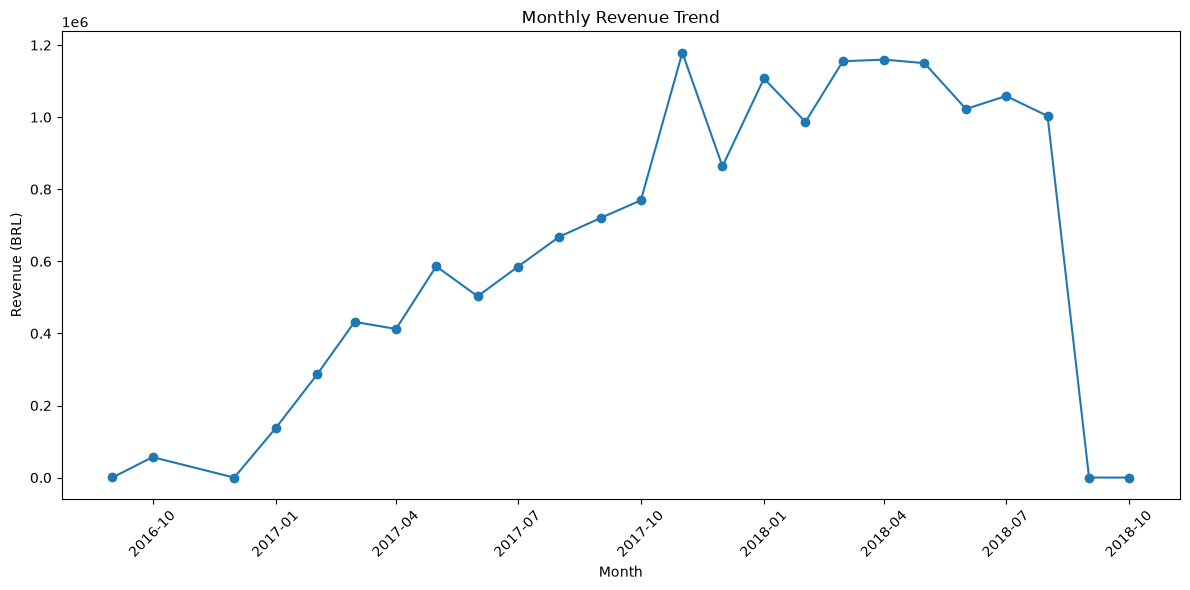

,sales_month,order_count,total_revenue,average_order_value
13,2017-11-01,7544,1179143.77,158.253090
18,2018-04-01,6939,1159698.04,167.248059
17,2018-03-01,7211,1155126.82,160.702117
19,2018-05-01,6873,1149781.82,167.777881
15,2018-01-01,7269,1107301.89,153.365913
21,2018-07-01,6292,1058728.03,168.775391
20,2018-06-01,6167,1022677.11,166.019011
22,2018-08-01,6512,1003308.47,155.503483
16,2018-02-01,6728,986908.96,147.431873
14,2017-12-01,5673,863547.23,153.546805


In [14]:
monthly_sales = calculate_monthly_sales(
    orders,
    order_items
)

monthly_sales.head()

monthly_sales.describe()

print("Number of months:", len(monthly_sales))
print(
    "Total revenue:",
    round(monthly_sales["total_revenue"].sum(), 2)
)
print(
    "Total orders:",
    monthly_sales["order_count"].sum()
)

plot_monthly_revenue(monthly_sales)

monthly_sales.nlargest(
    10,
    "total_revenue"
)[
    [
        "sales_month",
        "order_count",
        "total_revenue",
        "average_order_value",
    ]
]

## 4. Product Category Analysis

We analyze product-level sales performance across product categories.

Key metrics:

- Item count
- Order count
- Product count
- Merchandise revenue
- Freight revenue
- Total item value
- Average item price

Number of categories: 74
Total merchandise revenue: 13591643.7
Total item value: 15843553.24


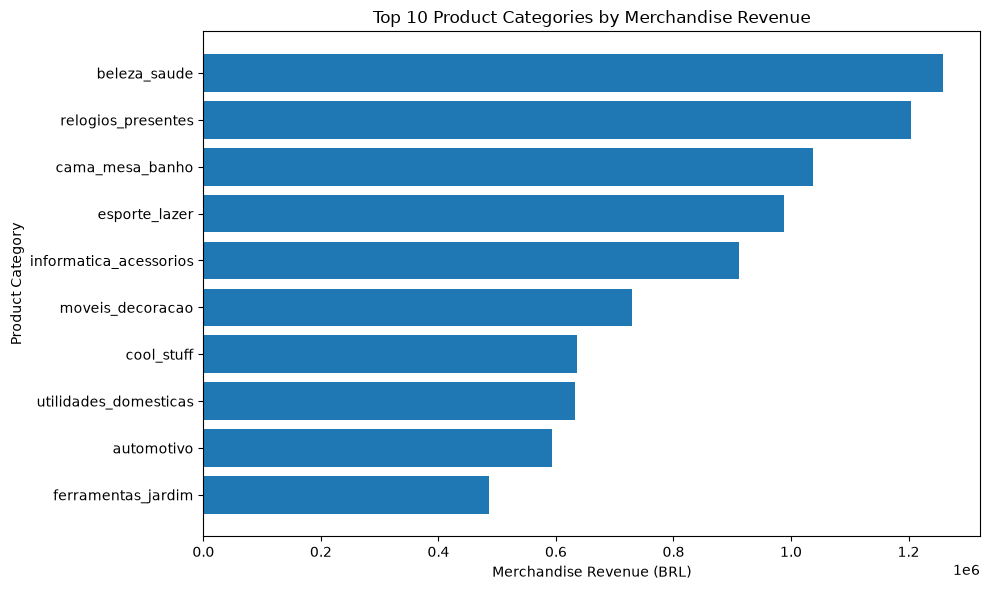

,product_category_name,average_item_price,merchandise_revenue,order_count
62,pcs,1098.340542,222963.13,181
65,portateis_casa_forno_e_cafe,624.285658,47445.71,75
30,eletrodomesticos_2,476.124958,113317.74,234
1,agro_industria_e_comercio,342.124858,72530.47,182
46,instrumentos_musicais,281.616000,191498.88,628
32,eletroportateis,280.778468,190648.58,630
66,portateis_cozinha_e_preparadores_de_alimentos,264.568667,3968.53,14
72,telefonia_fixa,225.693182,59583.00,217
26,construcao_ferramentas_seguranca,208.992371,40544.52,167
67,relogios_presentes,201.135984,1205005.68,5624


In [15]:
category_sales = calculate_category_sales(
    order_items,
    products
)

category_sales.head(10)

print("Number of categories:", len(category_sales))

print(
    "Total merchandise revenue:",
    round(category_sales["merchandise_revenue"].sum(), 2)
)

print(
    "Total item value:",
    round(category_sales["total_item_value"].sum(), 2)
)

top_categories = category_sales.head(10)

top_categories[
    [
        "product_category_name",
        "order_count",
        "product_count",
        "merchandise_revenue",
        "average_item_price",
    ]
]

plot_category_revenue(
    category_sales,
    top_n=10
)

category_sales.nlargest(
    10,
    "average_item_price"
)[
    [
        "product_category_name",
        "average_item_price",
        "merchandise_revenue",
        "order_count",
    ]
]

## 5. Customer Behavior Analysis

We analyze customer purchasing behavior using `customer_unique_id` as the customer-level identifier.

The analysis focuses on:

- Orders per customer
- One-time vs repeat purchasing
- Customer segmentation
- Geographic distribution of customers

Unique customers: 96096
Total customer records: 96096


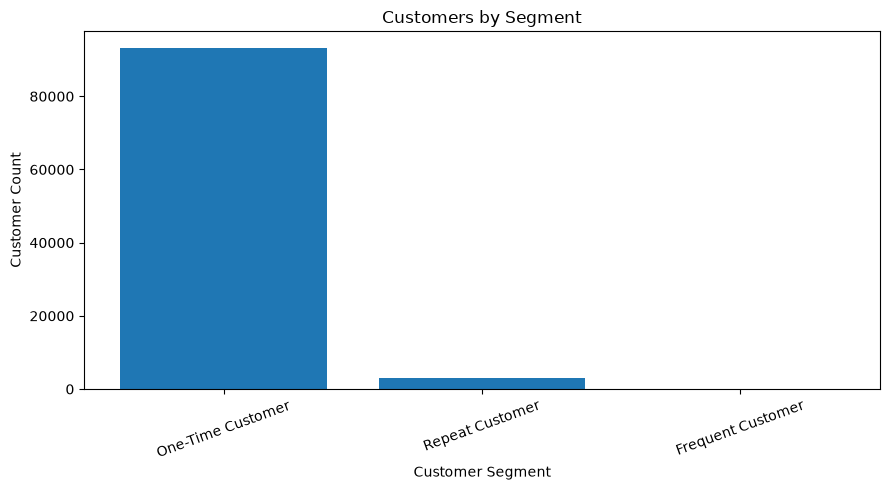

Repeat customers: 2997
Repeat customer rate: 3.12%


order_count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64

In [16]:
customer_behavior = calculate_customer_behavior(
    orders,
    customers
)

customer_behavior.head()

print(
    "Unique customers:",
    customer_behavior["customer_unique_id"].nunique()
)

print(
    "Total customer records:",
    len(customer_behavior)
)

segment_counts = (
    customer_behavior["customer_segment"]
    .value_counts()
)

segment_counts

segment_distribution = (
    customer_behavior["customer_segment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("percentage")
)

segment_distribution

plot_customer_segments(
    customer_behavior
)

repeat_customers = customer_behavior[
    customer_behavior["order_count"] > 1
]

repeat_customer_rate = (
    len(repeat_customers)
    / len(customer_behavior)
)

print(
    "Repeat customers:",
    len(repeat_customers)
)

print(
    "Repeat customer rate:",
    f"{repeat_customer_rate:.2%}"
)

customer_behavior[
    "order_count"
].value_counts().sort_index().head(10)



## 6. Delivery Performance Analysis

We analyze delivery performance using:

- Delivered orders
- On-time orders
- Late orders
- Late delivery rate
- Average delivery time
- Difference between actual and estimated delivery dates

In [17]:
delivery_metrics = calculate_delivery_metrics(orders)

delivery_metrics

print(
    "Delivered orders:",
    delivery_metrics["delivered_orders"]
)

print(
    "On-time orders:",
    delivery_metrics["on_time_orders"]
)

print(
    "Late orders:",
    delivery_metrics["late_orders"]
)

print(
    "Late delivery rate:",
    f"{delivery_metrics['late_delivery_rate']:.2%}"
)

print(
    "Average delivery days:",
    round(
        delivery_metrics["average_delivery_days"],
        2
    )
)

delivery_summary = pd.DataFrame(
    {
        "Metric": [
            "Delivered Orders",
            "On-Time Orders",
            "Late Orders",
            "Late Delivery Rate",
            "Average Delivery Days",
            "Average Difference vs Estimated",
        ],
        "Value": [
            delivery_metrics["delivered_orders"],
            delivery_metrics["on_time_orders"],
            delivery_metrics["late_orders"],
            f"{delivery_metrics['late_delivery_rate']:.2%}",
            round(
                delivery_metrics["average_delivery_days"],
                2
            ),
            round(
                delivery_metrics[
                    "average_delivery_vs_estimated_days"
                ],
                2
            ),
        ],
    }
)

delivery_summary



Delivered orders: 96476
On-time orders: 88649
Late orders: 7827
Late delivery rate: 8.11%
Average delivery days: 12.56


,Metric,Value
0,Delivered Orders,96476
1,On-Time Orders,88649
2,Late Orders,7827
3,Late Delivery Rate,8.11%
4,Average Delivery Days,12.56
5,Average Difference vs Estimated,-11.18


## 7. Key Analytical Findings

### Sales Performance

- The dataset contains approximately 99K orders.
- Total revenue from order items and freight is approximately 15.84M BRL.
- Monthly analysis shows how sales evolved throughout the observed period.

### Product Performance

- Product categories differ substantially in merchandise revenue and average item price.
- The highest-revenue categories contribute a significant share of merchandise sales.

### Customer Behavior

- The customer base is heavily concentrated among one-time customers.
- Repeat customers represent approximately 3.12% of the customer base when repeat customers are defined as customers with more than one order.
- Customer segmentation provides a basis for retention analysis.

### Delivery Performance

- Approximately 6.77% of classified delivered orders were late.
- Average delivery time was approximately 12 days.
- Comparing actual delivery dates with estimated dates helps identify periods and orders with delivery delays.

## Conclusion

The exploratory analysis provides a Python-based view of sales, product, customer, and delivery performance.

The results are complemented by the PostgreSQL analytical layer and the interactive Power BI dashboard developed as part of RetailPulse.